In [3]:

from pathlib import Path
from collections import Counter

# Replace this with your actual extracted FabricD folder path
fabricd_path = Path(r"C:\Users\pc\FabriDFabric Defect Detection Dataset")

if not fabricd_path.exists():
    print("Dataset folder not found. Check the path.")
else:
    print("FABRICD DATASET STRUCTURE")
    print("=" * 60)
    print("Dataset path:", fabricd_path)

    print("\nTop-level files and folders:")
    for item in sorted(fabricd_path.iterdir()):
        print("📁" if item.is_dir() else "📄", item.name)

    all_files = [p for p in fabricd_path.rglob("*") if p.is_file()]

    print("\nTotal files:", len(all_files))

    extensions = Counter(p.suffix.lower() for p in all_files)

    print("\nFile types:")
    for extension, count in extensions.most_common():
        print(f"{extension or '[no extension]'}: {count}")

    print("\nSample files:")
    for p in all_files[:20]:
        print(p.relative_to(fabricd_path))


FABRICD DATASET STRUCTURE
Dataset path: C:\Users\pc\FabriDFabric Defect Detection Dataset

Top-level files and folders:
📄 Febric Defect Detection and Segm.yolov.zip

Total files: 1

File types:
.zip: 1

Sample files:
Febric Defect Detection and Segm.yolov.zip


In [4]:

from pathlib import Path
import zipfile

fabricd_path = Path(
    r"C:\Users\pc\FabriDFabric Defect Detection Dataset"
)

zip_path = fabricd_path / "Febric Defect Detection and Segm.yolov.zip"

extract_path = fabricd_path / "FabricD_Extracted"

extract_path.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("FabricD dataset extracted successfully!")
print("Extracted location:", extract_path)

print("\nExtracted folders and files:")
for item in sorted(extract_path.iterdir()):
    print("📁" if item.is_dir() else "📄", item.name)


FabricD dataset extracted successfully!
Extracted location: C:\Users\pc\FabriDFabric Defect Detection Dataset\FabricD_Extracted

Extracted folders and files:
📄 data.yaml
📄 README.dataset.txt
📄 README.roboflow.txt
📁 test
📁 train
📁 valid


In [5]:

from pathlib import Path
from collections import Counter
import yaml

fabricd_path = Path(
    r"C:\Users\pc\FabriDFabric Defect Detection Dataset\FabricD_Extracted"
)

# Read dataset configuration
with open(fabricd_path / "data.yaml", "r", encoding="utf-8") as f:
    config = yaml.safe_load(f)

print("FABRICD DATASET ANALYSIS")
print("=" * 60)

print("\nDataset configuration:")
print(config)

# Extract class names
names = config.get("names", [])
if isinstance(names, dict):
    names = [names[k] for k in sorted(names, key=lambda x: int(x))]

print("\nNumber of classes:", len(names))
print("Defect classes:")
for i, name in enumerate(names):
    print(f"  {i}: {name}")

image_extensions = {".jpg", ".jpeg", ".png", ".webp", ".bmp"}

total_images = 0
total_labels = 0
class_counts = Counter()

print("\nDATASET DISTRIBUTION")
print("-" * 60)

for split in ["train", "valid", "test"]:
    images_dir = fabricd_path / split / "images"
    labels_dir = fabricd_path / split / "labels"

    images = (
        [p for p in images_dir.rglob("*")
         if p.is_file() and p.suffix.lower() in image_extensions]
        if images_dir.exists() else []
    )

    labels = (
        list(labels_dir.rglob("*.txt"))
        if labels_dir.exists() else []
    )

    split_counts = Counter()

    for label_file in labels:
        with open(label_file, "r", encoding="utf-8-sig") as f:
            for line in f:
                parts = line.strip().split()

                if not parts:
                    continue

                try:
                    class_id = int(parts[0])
                    split_counts[class_id] += 1
                    class_counts[class_id] += 1
                except ValueError:
                    print("Invalid class ID:", label_file.name)

    total_images += len(images)
    total_labels += len(labels)

    print(f"\n{split.upper()}")
    print("Images:", len(images))
    print("Label files:", len(labels))
    print("Annotated instances:", sum(split_counts.values()))

print("\n" + "=" * 60)
print("TOTAL IMAGES:", total_images)
print("TOTAL LABEL FILES:", total_labels)
print("TOTAL ANNOTATED INSTANCES:", sum(class_counts.values()))

print("\nCLASS DISTRIBUTION")
print("-" * 60)

for class_id, name in enumerate(names):
    print(f"{name}: {class_counts[class_id]} instances")


FABRICD DATASET ANALYSIS

Dataset configuration:
{'train': '../train/images', 'val': '../valid/images', 'test': '../test/images', 'nc': 4, 'names': ['Needle Mark Defect', 'hole Defect', 'missing yarn Defect', 'stain Defect'], 'roboflow': {'workspace': 'sabbir-ahmed-rony-s-workspace', 'project': 'febric-defect-detection-and-segm', 'version': 9, 'license': 'CC BY 4.0', 'url': 'https://universe.roboflow.com/sabbir-ahmed-rony-s-workspace/febric-defect-detection-and-segm/dataset/9'}}

Number of classes: 4
Defect classes:
  0: Needle Mark Defect
  1: hole Defect
  2: missing yarn Defect
  3: stain Defect

DATASET DISTRIBUTION
------------------------------------------------------------

TRAIN
Images: 1685
Label files: 1685
Annotated instances: 1714

VALID
Images: 364
Label files: 364
Annotated instances: 395

TEST
Images: 358
Label files: 358
Annotated instances: 393

TOTAL IMAGES: 2407
TOTAL LABEL FILES: 2407
TOTAL ANNOTATED INSTANCES: 2502

CLASS DISTRIBUTION
------------------------------

In [6]:

from pathlib import Path
from collections import Counter

fabricd_path = Path(
    r"C:\Users\pc\FabriDFabric Defect Detection Dataset\FabricD_Extracted"
)

image_extensions = {".jpg", ".jpeg", ".png", ".webp", ".bmp"}

stats = Counter()
annotation_formats = Counter()
invalid_examples = []

for split in ["train", "valid", "test"]:
    images_dir = fabricd_path / split / "images"
    labels_dir = fabricd_path / split / "labels"

    images = {
        p.stem for p in images_dir.iterdir()
        if p.is_file() and p.suffix.lower() in image_extensions
    }

    labels = {
        p.stem for p in labels_dir.glob("*.txt")
    }

    missing = images - labels
    orphan = labels - images

    stats["missing_labels"] += len(missing)
    stats["orphan_labels"] += len(orphan)

    for label_file in labels_dir.glob("*.txt"):
        lines = [
            line.strip()
            for line in label_file.read_text(
                encoding="utf-8-sig"
            ).splitlines()
            if line.strip()
        ]

        if not lines:
            stats["empty_label_files"] += 1

        seen = set()

        for line in lines:
            parts = line.split()

            if line in seen:
                stats["duplicate_annotations"] += 1
            seen.add(line)

            try:
                values = [float(x) for x in parts]
                class_id = values[0]

                if not class_id.is_integer() or not (
                    0 <= class_id < 4
                ):
                    raise ValueError("Invalid class ID")

                coords = values[1:]

                if len(parts) == 5:
                    annotation_formats["bounding_box"] += 1

                    x, y, w, h = coords

                    if not (
                        0 <= x <= 1 and
                        0 <= y <= 1 and
                        0 < w <= 1 and
                        0 < h <= 1 and
                        x - w / 2 >= -1e-6 and
                        x + w / 2 <= 1 + 1e-6 and
                        y - h / 2 >= -1e-6 and
                        y + h / 2 <= 1 + 1e-6
                    ):
                        raise ValueError(
                            "Invalid bounding box coordinates"
                        )

                elif len(coords) >= 6 and len(coords) % 2 == 0:
                    annotation_formats["segmentation"] += 1

                    if not all(0 <= v <= 1 for v in coords):
                        raise ValueError(
                            "Invalid polygon coordinates"
                        )

                else:
                    raise ValueError("Unexpected annotation format")

            except (ValueError, IndexError) as e:
                stats["invalid_annotations"] += 1

                if len(invalid_examples) < 10:
                    invalid_examples.append(
                        (str(label_file.name), str(e))
                    )

print("FABRICD ANNOTATION QUALITY REPORT")
print("=" * 55)

print("\nAnnotation formats:")
for name, count in annotation_formats.items():
    print(f"{name}: {count}")

print("\nQuality checks:")
for name in [
    "missing_labels",
    "orphan_labels",
    "empty_label_files",
    "duplicate_annotations",
    "invalid_annotations"
]:
    print(f"{name}: {stats[name]}")

print("\nSample invalid annotations:")
for filename, reason in invalid_examples:
    print(filename, "->", reason)

print("\nAnalysis completed. No files were modified.")


FABRICD ANNOTATION QUALITY REPORT

Annotation formats:
segmentation: 2502

Quality checks:
missing_labels: 0
orphan_labels: 0
empty_label_files: 613
duplicate_annotations: 0
invalid_annotations: 0

Sample invalid annotations:

Analysis completed. No files were modified.


In [7]:

import pandas as pd
from pathlib import Path

# Save analysis evidence separately from the original dataset
output_dir = fabricd_path.parent / "FabricD_Analysis_Results"
output_dir.mkdir(parents=True, exist_ok=True)

fabricd_stats = {
    "Dataset": "FabricD",
    "Total Images": 2407,
    "Train Images": 1685,
    "Validation Images": 364,
    "Test Images": 358,
    "Defect Classes": 4,
    "Annotated Instances": 2502,
    "Annotation Format": "YOLO Segmentation",
    "Missing Labels": 0,
    "Orphan Labels": 0,
    "Empty Label Files": 613,
    "Duplicate Annotations": 0,
    "Invalid Annotations": 0
}

df = pd.DataFrame([fabricd_stats])

csv_path = output_dir / "fabricd_statistics.csv"
df.to_csv(csv_path, index=False)

print("FabricD analysis saved successfully!")
print("File:", csv_path)

display(df)


FabricD analysis saved successfully!
File: C:\Users\pc\FabriDFabric Defect Detection Dataset\FabricD_Analysis_Results\fabricd_statistics.csv


,Dataset,Total Images,Train Images,Validation Images,Test Images,Defect Classes,Annotated Instances,Annotation Format,Missing Labels,Orphan Labels,Empty Label Files,Duplicate Annotations,Invalid Annotations
0,FabricD,2407,1685,364,358,4,2502,YOLO Segmentation,0,0,613,0,0


In [9]:

from pathlib import Path
from collections import Counter
import pandas as pd
import yaml

bdfd9_path = Path(
    r"C:\Users\pc\BDFD9 Bangladesh Centric Fabric Defect Dataset"
    r"\extracted\BDFD9_YOLO"
)

with open(bdfd9_path / "data.yaml", encoding="utf-8") as f:
    config = yaml.safe_load(f)

names = config["names"]

if isinstance(names, dict):
    names = [names[k] for k in sorted(names, key=int)]

image_extensions = {".jpg", ".jpeg", ".png", ".webp", ".bmp"}

records = []
class_counts = Counter()

for split in ["train", "valid", "test"]:
    images_dir = bdfd9_path / split / "images"
    labels_dir = bdfd9_path / split / "labels"

    images = [
        p for p in images_dir.rglob("*")
        if p.is_file() and p.suffix.lower() in image_extensions
    ]

    labels = list(labels_dir.rglob("*.txt"))
    instances = 0

    for label in labels:
        for line in label.read_text(
            encoding="utf-8-sig"
        ).splitlines():
            parts = line.split()

            if not parts:
                continue

            class_id = int(parts[0])
            class_counts[class_id] += 1
            instances += 1

    records.append({
        "Split": split,
        "Images": len(images),
        "Label Files": len(labels),
        "Defect Instances": instances
    })

df = pd.DataFrame(records)

print("BDFD9 DATASET DISTRIBUTION")
display(df)

print("\nBDFD9 CLASS DISTRIBUTION")

class_df = pd.DataFrame([
    {
        "Class ID": i,
        "Defect Class": name,
        "Instances": class_counts[i]
    }
    for i, name in enumerate(names)
])

display(class_df)

# Save evidence
output_dir = bdfd9_path.parent / "Dataset_Analysis_Results"
output_dir.mkdir(parents=True, exist_ok=True)

df.to_csv(
    output_dir / "bdfd9_distribution.csv",
    index=False
)

class_df.to_csv(
    output_dir / "bdfd9_class_distribution.csv",
    index=False
)

print("\nEvidence saved to:", output_dir)


BDFD9 DATASET DISTRIBUTION


,Split,Images,Label Files,Defect Instances
0,train,775,775,1017
1,valid,208,208,244
2,test,105,105,127



BDFD9 CLASS DISTRIBUTION


,Class ID,Defect Class,Instances
0,0,DropStitch,127
1,1,Hole,122
2,2,Horizontal Mark,95
3,3,Knot,114
4,4,Oil Spot,154
5,5,Setup,130
6,6,Slub,118
7,7,Vertical LineMark,299
8,8,Yurn Dust,229



Evidence saved to: C:\Users\pc\BDFD9 Bangladesh Centric Fabric Defect Dataset\extracted\Dataset_Analysis_Results


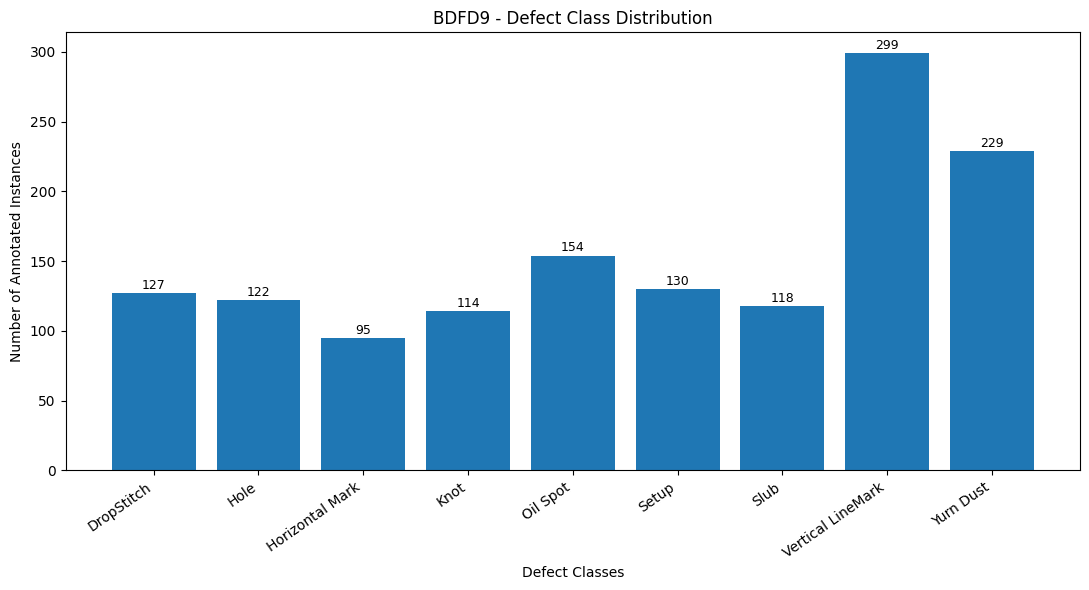

Graph saved: C:\Users\pc\BDFD9 Bangladesh Centric Fabric Defect Dataset\extracted\Dataset_Analysis_Results\bdfd9_class_distribution.png


In [10]:

import matplotlib.pyplot as plt

# Use previously calculated BDFD9 class statistics
fig, ax = plt.subplots(figsize=(11, 6))

bars = ax.bar(
    class_df["Defect Class"],
    class_df["Instances"]
)

ax.set_title("BDFD9 - Defect Class Distribution")
ax.set_xlabel("Defect Classes")
ax.set_ylabel("Number of Annotated Instances")

plt.xticks(rotation=35, ha="right")

for bar in bars:
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 3,
        str(int(bar.get_height())),
        ha="center",
        fontsize=9
    )

plt.tight_layout()

graph_path = output_dir / "bdfd9_class_distribution.png"

plt.savefig(
    graph_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Graph saved:", graph_path)


DATASET COMPARISON


,Dataset,Total Images,Train Images,Validation Images,Test Images,Defect Classes
0,BDFD9,1088,775,208,105,9
1,FabricD,2407,1685,364,358,4


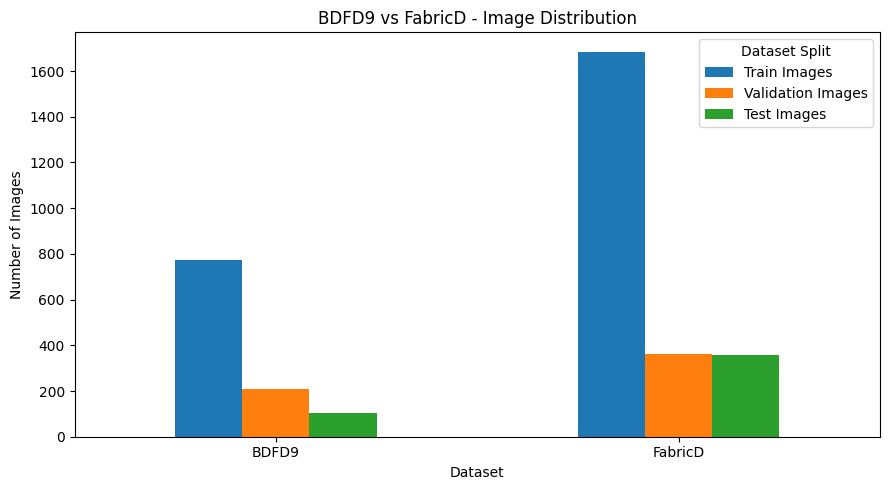

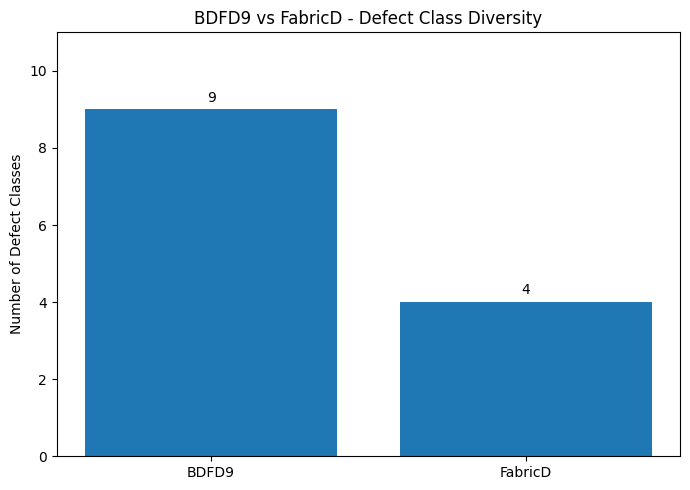


Comparison evidence saved in:
C:\Users\pc\FabriDFabric Defect Detection Dataset\FabricD_Analysis_Results


In [8]:

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Output folder
output_dir = fabricd_path.parent / "FabricD_Analysis_Results"
output_dir.mkdir(parents=True, exist_ok=True)

# Verified dataset statistics
comparison = pd.DataFrame({
    "Dataset": ["BDFD9", "FabricD"],
    "Total Images": [1088, 2407],
    "Train Images": [775, 1685],
    "Validation Images": [208, 364],
    "Test Images": [105, 358],
    "Defect Classes": [9, 4]
})

# Save comparison CSV
csv_path = output_dir / "dataset_comparison.csv"
comparison.to_csv(csv_path, index=False)

print("DATASET COMPARISON")
display(comparison)

# Graph 1: Image distribution
ax = comparison.set_index("Dataset")[
    ["Train Images", "Validation Images", "Test Images"]
].plot(kind="bar", figsize=(9, 5))

ax.set_title("BDFD9 vs FabricD - Image Distribution")
ax.set_ylabel("Number of Images")
ax.set_xlabel("Dataset")
ax.tick_params(axis="x", rotation=0)
ax.legend(title="Dataset Split")

plt.tight_layout()
plt.savefig(
    output_dir / "image_distribution_comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# Graph 2: Number of defect classes
fig, ax = plt.subplots(figsize=(7, 5))

bars = ax.bar(
    comparison["Dataset"],
    comparison["Defect Classes"]
)

ax.set_title("BDFD9 vs FabricD - Defect Class Diversity")
ax.set_ylabel("Number of Defect Classes")
ax.set_ylim(0, 11)

for bar in bars:
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.2,
        str(int(bar.get_height())),
        ha="center"
    )

plt.tight_layout()
plt.savefig(
    output_dir / "class_diversity_comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("\nComparison evidence saved in:")
print(output_dir)
